--- Generowanie sztucznych danych szeregów czasowych ---
--- Analiza i wykrywanie anomalii ---
Wykryto 2 podejrzanych punktów danych (anomalii).



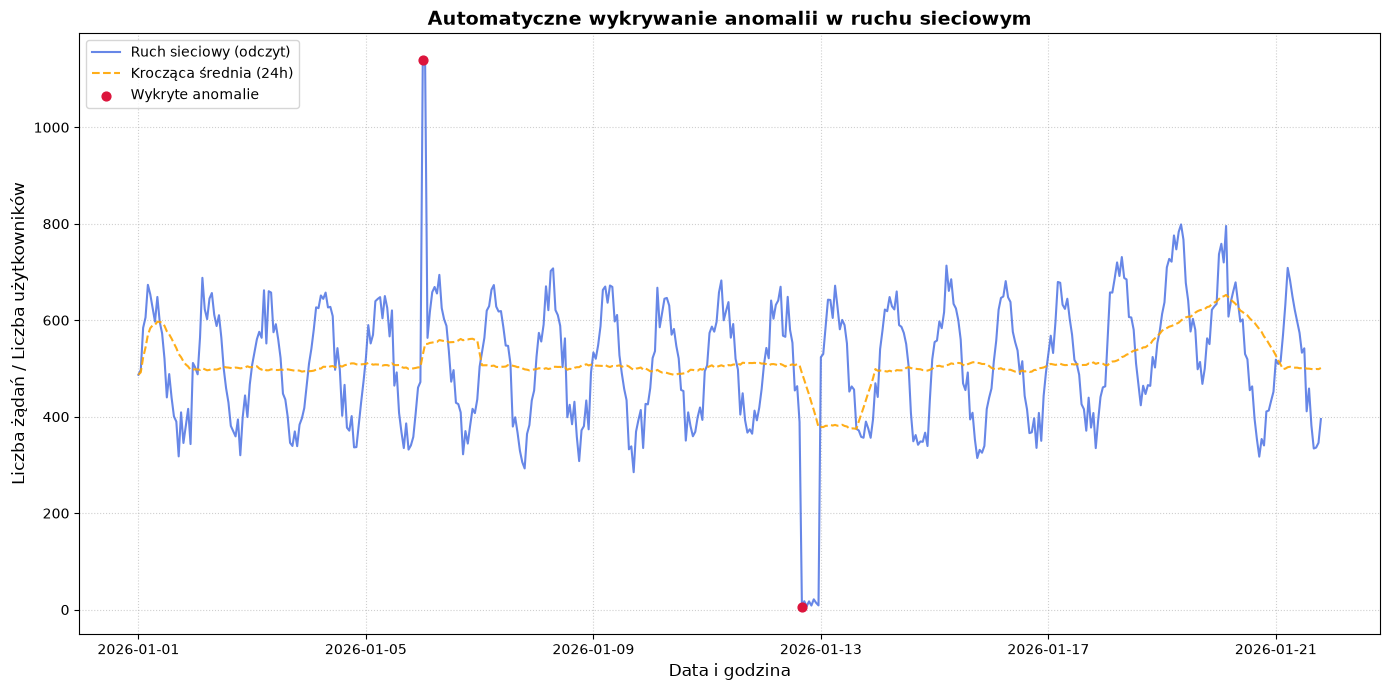

In [4]:
# ==========================================
# 1. GENEROWANIE DANYCH RUCHU SIECIOWEGO Z SZUMEM
# ==========================================
print("--- Generowanie sztucznych danych szeregów czasowych ---")
np.random.seed(2026)

# Tworzymy 500 punktów czasowych (używamy małego 'h' dla nowej wersji Pandas)
timestamps = pd.date_range(start="2026-01-01", periods=500, freq="h")

# Podstawowy sygnał: wzorzec dzienny (sinusoida) + losowy szum
base_traffic = 500 + 150 * np.sin(2 * np.pi * timestamps.hour / 24)
noise = np.random.normal(loc=0, scale=30, size=len(timestamps))
traffic = base_traffic + noise

# Tworzymy DataFrame na samym początku
df = pd.DataFrame({"Ruch": traffic.copy()}, index=timestamps)

# ==========================================
# 2. WSTRZYKIWANIE ANOMALII (AWARIE I SKOKI) - POPRAWIONE
# ==========================================
# Anomalia typu 1: Nagły, gigantyczny skok (np. atak DDoS lub viralowy post)
df.iloc[120, df.columns.get_loc('Ruch')] = df.iloc[120]['Ruch'] + 600
df.iloc[121, df.columns.get_loc('Ruch')] = df.iloc[121]['Ruch'] + 550

# Anomalia typu 2: Awaria systemu (nagły spadek do zera i zawieszenie na kilka godzin)
df.iloc[280:288, df.columns.get_loc('Ruch')] = 10 + np.random.normal(0, 5, size=8)

# Anomalia typu 3: Dryf danych (stopniowy, nienaturalny wzrost)
df.iloc[400:460, df.columns.get_loc('Ruch')] = df.iloc[400:460]['Ruch'] + np.linspace(0, 200, 60)


# ==========================================
# 3. WYKRYWANIE ANOMALII (KROCZĄCY Z-SCORE)
# ==========================================
print("--- Analiza i wykrywanie anomalii ---")

window_size = 24
threshold = 3.0

# Obliczamy kroczącą średnią i odchylenie standardowe
df['Rolling_Mean'] = df['Ruch'].rolling(window=window_size, min_periods=1).mean()
df['Rolling_Std'] = df['Ruch'].rolling(window=window_size, min_periods=1).std()

# Obliczamy Z-Score i oznaczamy anomalie
df['Z_Score'] = (df['Ruch'] - df['Rolling_Mean']) / df['Rolling_Std']
df['Is_Anomaly'] = df['Z_Score'].abs() > threshold

anomalies_count = df['Is_Anomaly'].sum()
print(f"Wykryto {anomalies_count} podejrzanych punktów danych (anomalii).\n")

# ==========================================
# 4. WIZUALIZACJA WYNIKÓW (Matplotlib)
# ==========================================
plt.figure(figsize=(14, 7))

# Wykres oryginalnego ruchu
plt.plot(df.index, df['Ruch'], label='Ruch sieciowy (odczyt)', color='royalblue', alpha=0.8)

# Wykres kroczącej średniej (linia trendu)
plt.plot(df.index, df['Rolling_Mean'], label='Krocząca średnia (24h)', color='orange', linestyle='--', alpha=0.9)

# Zaznaczenie wykrytych anomalii czerwonymi punktami
anomalies = df[df['Is_Anomaly']]
plt.scatter(anomalies.index, anomalies['Ruch'], color='crimson', label='Wykryte anomalie', zorder=5, s=40)

# Formatowanie wykresu
plt.title('Automatyczne wykrywanie anomalii w ruchu sieciowym', fontsize=14, fontweight='bold')
plt.xlabel('Data i godzina', fontsize=12)
plt.ylabel('Liczba żądań / Liczba użytkowników', fontsize=12)
plt.legend(loc='upper left', frameon=True)
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()
